In [1]:
from google.colab import files
uploaded = files.upload()   # utils.py, dataset_base.csv, dataset_with_technicals.csv

Saving dataset_base.csv to dataset_base.csv
Saving dataset_with_technicals.csv to dataset_with_technicals.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from fastai.tabular.all import *
from utils import load_split, evaluate

import fastai
print(fastai.__version__, torch.__version__)

paths = {"base": "dataset_base.csv", "tech": "dataset_with_technicals.csv"}

2.8.12 2.11.0+cpu


In [12]:
class LossLog(Callback):
    order = 70   # runs after fastai's Recorder, so its log row exists
    def before_fit(self):
        self.rows = []
    def after_epoch(self):
        # recorder.log = [epoch, train_loss, valid_loss, rmse, time]
        self.rows.append([float(self.recorder.log[1]), float(self.recorder.log[2])])


def run_fastai(path, name, seeds=range(3), layers=[32, 16], wd=0.1, epochs=40):
    X_tr, X_te, y_tr, y_te = load_split(path)
    feats = list(X_tr.columns)

    train_df = X_tr.copy(); train_df["target"] = y_tr.values
    test_df = X_te.copy();  test_df["target"] = y_te.values
    train_df = train_df.reset_index(drop=True)
    test_df = test_df.reset_index(drop=True)

    n = len(train_df)
    n_val = int(n * 0.15)
    splits = (list(range(0, n - n_val)), list(range(n - n_val, n)))

    # Standardize the target using the training-portion mean/std
    y_mu = train_df["target"].iloc[: n - n_val].mean()
    y_sd = train_df["target"].iloc[: n - n_val].std()
    train_df["target"] = (train_df["target"] - y_mu) / y_sd

    to = TabularPandas(
        train_df, procs=[Normalize], cont_names=feats, y_names="target",
        y_block=RegressionBlock(), splits=splits,
    )
    dls = to.dataloaders(bs=32)
    test_dl = dls.test_dl(test_df.assign(target=0.0))

    preds = []
    hist = None
    for s in seeds:
        set_seed(s, reproducible=True)
        learn = tabular_learner(
            dls, layers=layers,
            config=tabular_config(ps=[0.3, 0.3]),
            wd=wd, loss_func=MSELossFlat(), metrics=rmse,
        )
        ll = LossLog()
        learn.fit_one_cycle(
            epochs, 1e-3,
            cbs=[ll,
                 EarlyStoppingCallback(monitor="valid_loss", patience=8),
                 SaveModelCallback(monitor="valid_loss", fname=f"best_{name}_{s}")],
        )
        hist = np.array(ll.rows)          # losses of this seed, copied right after training
        p, _ = learn.get_preds(dl=test_dl)
        preds.append(p.numpy().ravel() * y_sd + y_mu)

    return np.mean(preds, axis=0), y_te, y_tr.mean(), hist


results, store = [], {}
for k, p in paths.items():
    pred, y_te, mu, hist = run_fastai(p, k)
    store[k] = dict(pred=pred, y_te=y_te, hist=hist)
    results.append({**evaluate(y_te, pred, mu, "fastai tabular"), "data": k})

res = pd.DataFrame(results).set_index(["data", "model"])
print(res.round(4))
res.to_csv("fastai_results.csv")

epoch,train_loss,valid_loss,_rmse,time
0,1.458545,1.793671,1.339280,00:00
1,1.467497,1.900621,1.378630,00:00
2,1.395607,1.922983,1.386717,00:00
3,1.304764,1.893794,1.376152,00:00
4,1.360967,1.849355,1.359910,00:00
5,1.333086,1.775566,1.332504,00:00
6,1.271329,1.732747,1.316338,00:00
7,1.213160,1.716225,1.310048,00:00
8,1.117758,1.698343,1.303205,00:00
9,1.049420,1.668979,1.291890,00:00


Better model found at epoch 0 with valid_loss value: 1.793670654296875.
Better model found at epoch 5 with valid_loss value: 1.7755656242370605.
Better model found at epoch 6 with valid_loss value: 1.7327466011047363.
Better model found at epoch 7 with valid_loss value: 1.7162247896194458.
Better model found at epoch 8 with valid_loss value: 1.6983433961868286.
Better model found at epoch 9 with valid_loss value: 1.6689785718917847.
Better model found at epoch 11 with valid_loss value: 1.6292879581451416.
No improvement since epoch 11: early stopping


epoch,train_loss,valid_loss,_rmse,time
0,1.361718,1.698765,1.303367,00:00
1,1.333688,1.822115,1.349857,00:00
2,1.335557,1.853283,1.361353,00:00
3,1.297655,1.883736,1.372492,00:00
4,1.237595,1.834418,1.354407,00:00
5,1.227173,1.828694,1.352292,00:00
6,1.191302,1.800086,1.341673,00:00
7,1.200916,1.756178,1.325209,00:00
8,1.203505,1.746307,1.321479,00:00


Better model found at epoch 0 with valid_loss value: 1.6987653970718384.
No improvement since epoch 0: early stopping


epoch,train_loss,valid_loss,_rmse,time
0,1.499482,1.709087,1.307320,00:00
1,1.373951,1.782081,1.334946,00:00
2,1.404937,1.801158,1.342072,00:00
3,1.352379,1.784448,1.335832,00:00
4,1.268071,1.779792,1.334088,00:00
5,1.235639,1.787701,1.337049,00:00
6,1.265692,1.726672,1.314029,00:00
7,1.170315,1.740047,1.319108,00:00
8,1.144815,1.678027,1.295387,00:00
9,1.111529,1.631274,1.277213,00:00


...

epoch,train_loss,valid_loss,_rmse,time
0,1.633091,1.691687,1.300648,00:00
1,1.655146,1.758670,1.326149,00:00
2,1.596417,1.770316,1.330532,00:00
3,1.522401,1.744809,1.320912,00:00
4,1.386568,1.703494,1.305180,00:00
5,1.409493,1.661796,1.289107,00:00
6,1.347395,1.649563,1.284353,00:00
7,1.295915,1.631372,1.277252,00:00
8,1.290857,1.643742,1.282085,00:00
9,1.203885,1.637836,1.279780,00:00


Better model found at epoch 0 with valid_loss value: 1.6916865110397339.
Better model found at epoch 5 with valid_loss value: 1.66179621219635.
Better model found at epoch 6 with valid_loss value: 1.6495634317398071.
Better model found at epoch 7 with valid_loss value: 1.6313716173171997.
Better model found at epoch 10 with valid_loss value: 1.614918828010559.
Better model found at epoch 11 with valid_loss value: 1.6098512411117554.
Better model found at epoch 12 with valid_loss value: 1.5860016345977783.
Better model found at epoch 13 with valid_loss value: 1.5808241367340088.
No improvement since epoch 13: early stopping


epoch,train_loss,valid_loss,_rmse,time
0,1.610701,1.639788,1.280542,00:00
1,1.678897,1.761091,1.327061,00:00
2,1.709684,1.768499,1.329849,00:00
3,1.682584,1.733966,1.316801,00:00
4,1.594369,1.806228,1.343960,00:00
5,1.569063,1.697924,1.303044,00:00
6,1.484837,1.671016,1.292678,00:00
7,1.397520,1.671202,1.292750,00:00
8,1.340040,1.639370,1.280379,00:00
9,1.318436,1.622899,1.273930,00:00


Better model found at epoch 0 with valid_loss value: 1.639788031578064.
Better model found at epoch 8 with valid_loss value: 1.6393702030181885.
Better model found at epoch 9 with valid_loss value: 1.6228985786437988.
Better model found at epoch 12 with valid_loss value: 1.6120342016220093.
Better model found at epoch 13 with valid_loss value: 1.597999930381775.
No improvement since epoch 13: early stopping


                       RMSE     MAE      R2  R2_OOS  DirAcc
data model                                                 
base fastai tabular  0.0363  0.0261  0.0218   0.023  0.5086
tech fastai tabular  0.0372  0.0267 -0.0210  -0.020  0.4971


(28, 2)


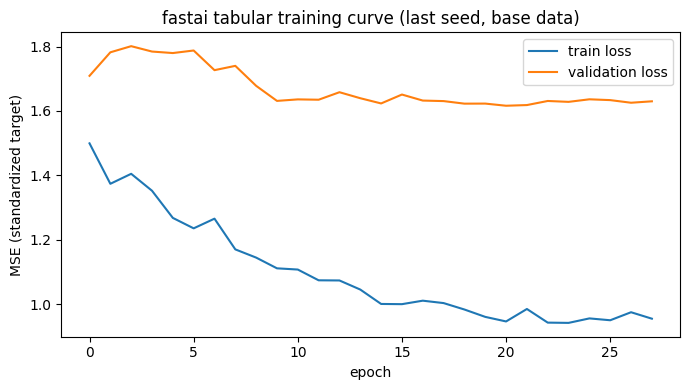

In [13]:
vals = store["base"]["hist"]
print(vals.shape)    # expect (number of epochs, 2)

plt.figure(figsize=(7, 4))
plt.plot(vals[:, 0], label="train loss")
plt.plot(vals[:, 1], label="validation loss")
plt.title("fastai tabular training curve (last seed, base data)")
plt.xlabel("epoch"); plt.ylabel("MSE (standardized target)")
plt.legend(); plt.tight_layout()
plt.savefig("14_fastai_loss_curve.png", dpi=150)
plt.show()

In [14]:
from google.colab import files
for f in ["fastai_results.csv", "13_fastai_pred_vs_actual.png", "14_fastai_loss_curve.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>